In [63]:
import time, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.feature_selection import mutual_info_regression

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

warnings.filterwarnings("ignore") # silences noisy messages
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # makes results reproducible
TARGET = "Health_Risk_Score" # avoids retyping the column name.

# Step 1: Explore the Dataset
# Load the dataset
df = pd.read_csv('Health_Risk_Prediction_Dataset.csv')
df

,Patient_ID,Age,BMI,BloodPressure,Cholesterol,Glucose,Smoking_History,Exercise_Frequency,Alcohol_Consumption,Family_History,Health_Risk_Score
0,1,30,30.9,90.0,244.0,127.0,Never,Frequent,NaN,Yes,70.3
1,2,68,30.1,NaN,224.0,91.0,Never,Rarely,Low,No,57.2
2,3,58,26.3,117.0,195.0,96.0,Never,Rarely,Low,No,54.3
3,4,75,21.8,127.0,219.0,81.0,Never,Rarely,Low,No,80.1
4,5,64,30.8,121.0,225.0,NaN,Never,Frequent,High,No,22.5
...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,65,29.7,124.0,249.0,108.0,Never,Rarely,NaN,No,69.6
9996,9997,43,37.4,130.0,134.0,112.0,Never,Moderate,Moderate,No,54.0
9997,9998,53,27.1,118.0,191.0,54.0,Current,NaN,Low,No,77.0
9998,9999,22,29.8,117.0,259.0,95.0,Former,Moderate,NaN,No,61.8


In [64]:
print("Shape:", df.shape)
print("Duplicate Patient_IDs:", df["Patient_ID"].duplicated().sum(), "| duplicate rows (excl. ID):", df.drop(columns="Patient_ID").duplicated().sum())
df.head()

Shape: (10000, 11)
Duplicate Patient_IDs: 0 | duplicate rows (excl. ID): 0


,Patient_ID,Age,BMI,BloodPressure,Cholesterol,Glucose,Smoking_History,Exercise_Frequency,Alcohol_Consumption,Family_History,Health_Risk_Score
0,1,30,30.9,90.0,244.0,127.0,Never,Frequent,NaN,Yes,70.3
1,2,68,30.1,NaN,224.0,91.0,Never,Rarely,Low,No,57.2
2,3,58,26.3,117.0,195.0,96.0,Never,Rarely,Low,No,54.3
3,4,75,21.8,127.0,219.0,81.0,Never,Rarely,Low,No,80.1
4,5,64,30.8,121.0,225.0,NaN,Never,Frequent,High,No,22.5


In [65]:
# Display basic information about the dataset
# Builds one table with each column’s type, missing count, missing percentage and number of distinct values.
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(),
})
summary

,dtype,missing,missing_%,unique
Patient_ID,int64,0,0.0,10000
Age,int64,0,0.0,72
BMI,float64,500,5.0,368
BloodPressure,float64,500,5.0,109
Cholesterol,float64,500,5.0,255
Glucose,float64,500,5.0,169
Smoking_History,object,0,0.0,3
Exercise_Frequency,object,2010,20.1,3
Alcohol_Consumption,object,5019,50.2,3
Family_History,object,0,0.0,2


In [66]:
# Check for value frequency in each column
for col in df.columns:
    print(f"\nValue counts for column '{col}':")
    print(df[col].value_counts())


Value counts for column 'Patient_ID':
Patient_ID
1        1
6671     1
6664     1
6665     1
6666     1
        ..
3334     1
3335     1
3336     1
3337     1
10000    1
Name: count, Length: 10000, dtype: int64

Value counts for column 'Age':
Age
39    172
82    163
75    160
56    160
47    157
     ... 
49    120
72    120
87    118
38    115
31    106
Name: count, Length: 72, dtype: int64

Value counts for column 'BMI':
BMI
26.4    77
25.9    76
25.8    75
27.0    71
25.7    68
        ..
48.1     1
11.9     1
11.2     1
9.3      1
42.7     1
Name: count, Length: 368, dtype: int64

Value counts for column 'BloodPressure':
BloodPressure
122.0    296
115.0    267
120.0    262
117.0    261
119.0    255
        ... 
173.0      1
172.0      1
179.0      1
174.0      1
178.0      1
Name: count, Length: 109, dtype: int64

Value counts for column 'Cholesterol':
Cholesterol
197.0    113
191.0    109
192.0    105
194.0    105
201.0    105
        ... 
311.0      1
333.0      1
321.0      1
7

In [67]:
# Drops the ID, since it is not a feature, and computes count, mean, std, min, quartiles and max.
df.drop(columns="Patient_ID").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,10000.0,53.52,20.66,18.0,36.00,54.0,71.0,89.0
BMI,9500.0,26.99,6.00,4.3,22.80,27.0,31.2,48.4
BloodPressure,9500.0,119.74,14.82,67.0,110.00,120.0,129.0,184.0
Cholesterol,9500.0,199.66,39.41,44.0,173.00,199.0,226.0,351.0
Glucose,9500.0,99.70,25.12,-2.0,83.00,100.0,117.0,194.0
Health_Risk_Score,10000.0,50.16,15.09,-17.1,40.18,50.3,60.3,109.0


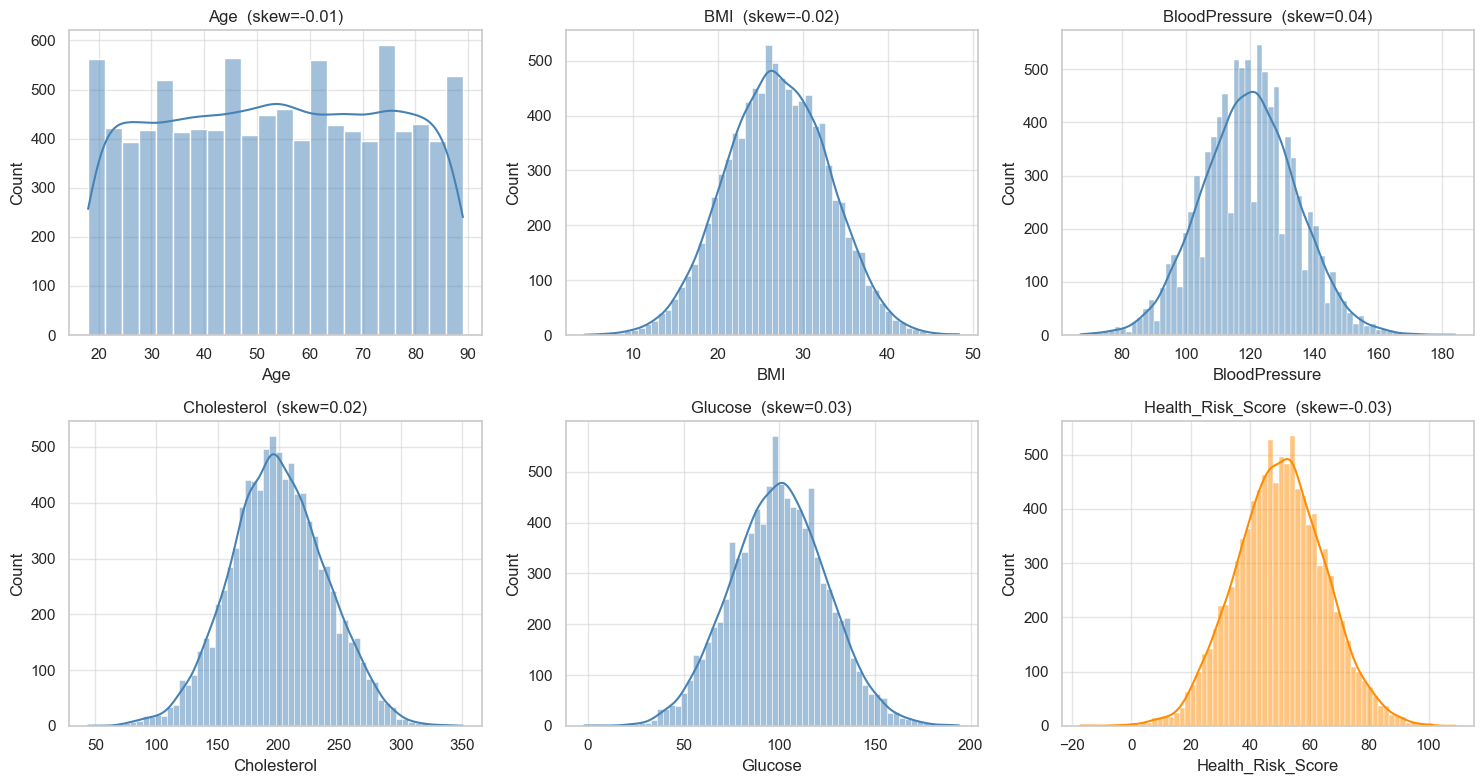

In [68]:
# Visualize the distribution of numerical features and the target variable
# Makes a 2x3 grid of plots. axes.ravel() flattens it so it can be paired with the 6 columns (5 features plus the target).
# Each plot is a histogram with a smoothed density curve (kde), and the title includes the skewness.
# The target gets orange and the features blue.
num_cols_raw = ["Age", "BMI", "BloodPressure", "Cholesterol", "Glucose"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols_raw + [TARGET]):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue" if col != TARGET else "darkorange")
    ax.set_title(f"{col}  (skew={df[col].skew():.2f})")
plt.tight_layout(); plt.show()

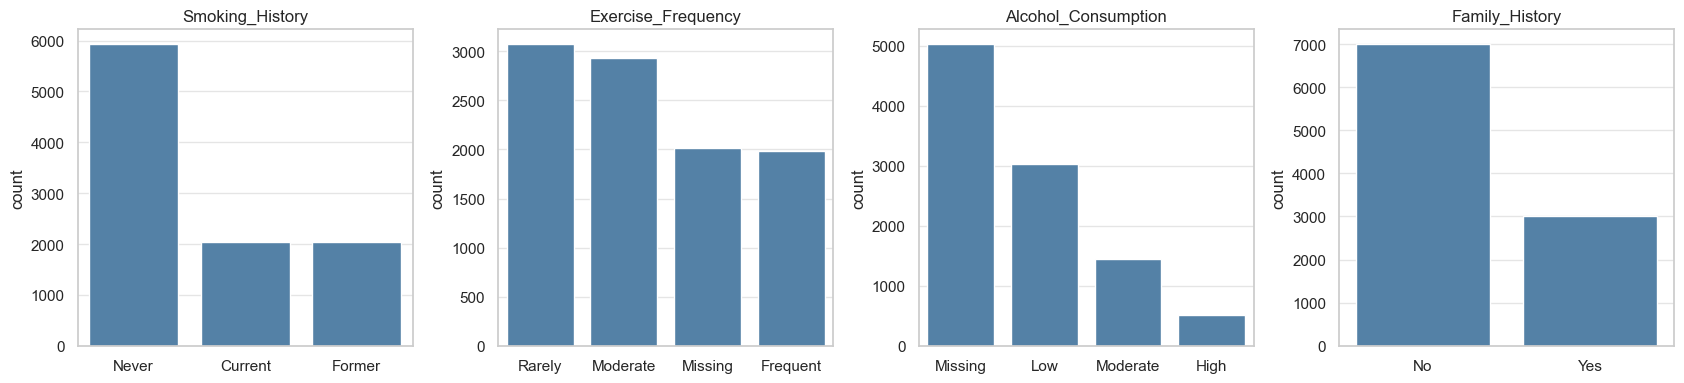

In [69]:
# Visualize the distribution of categorical features

# Makes a 1x4 grid of plots. Each plot is a countplot with the title including the number of unique values.

# fillna("Missing") makes missing values their own visible bar, and order sorts the bars from most to least frequent.

cat_cols_raw = ["Smoking_History", "Exercise_Frequency", "Alcohol_Consumption", "Family_History"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col in zip(axes, cat_cols_raw):
    order = df[col].fillna("Missing").value_counts().index
    sns.countplot(x=df[col].fillna("Missing"), order=order, ax=ax, color="steelblue")
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); plt.show()

BMI < 12            : 57
Glucose < 40        : 70 (min = -2.0 )
BloodPressure < 60  : 0
Cholesterol < 70    : 3
Target < 0          : 8
Target > 100        : 4


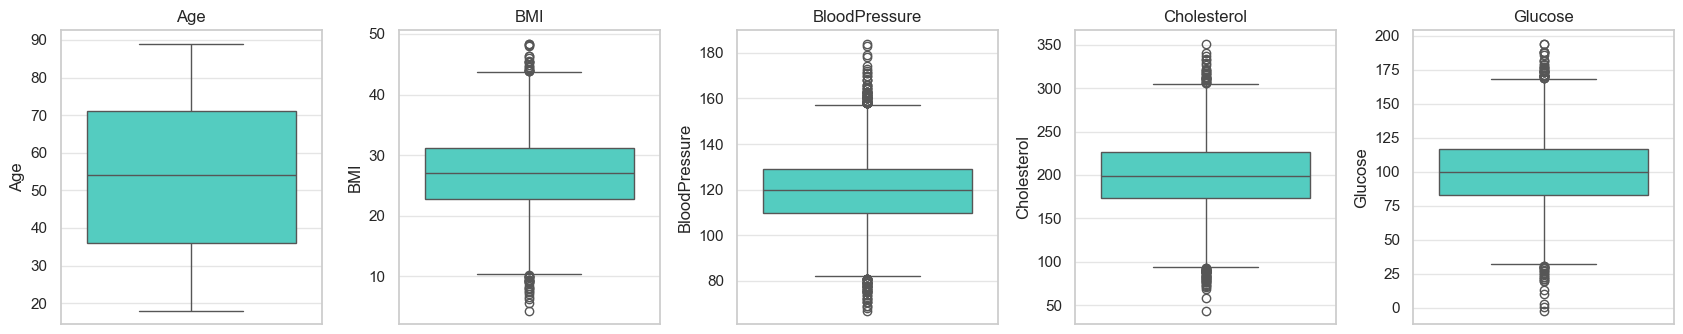

In [70]:
# Rows that look physiologically impossible, and target values outside the 0-100 score range
print("BMI < 12            :", (df.BMI < 12).sum())
print("Glucose < 40        :", (df.Glucose < 40).sum(), "(min =", df.Glucose.min(), ")")
print("BloodPressure < 60  :", (df.BloodPressure < 60).sum())
print("Cholesterol < 70    :", (df.Cholesterol < 70).sum())
print("Target < 0          :", (df[TARGET] < 0).sum())
print("Target > 100        :", (df[TARGET] > 100).sum())

fig, axes = plt.subplots(1, 5, figsize=(17, 3.5))
for ax, col in zip(axes, num_cols_raw):
    sns.boxplot(y=df[col], ax=ax, color="turquoise"); ax.set_title(col)
plt.tight_layout(); plt.show()

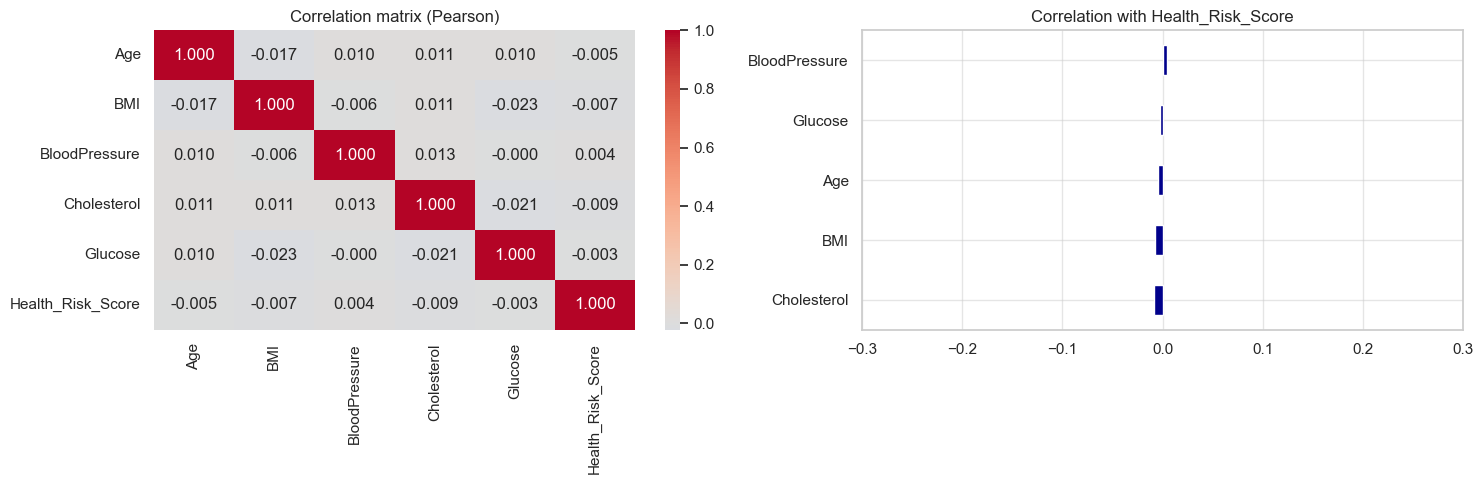

Mean Health_Risk_Score by category (missing shown as its own group):
                  mean    std  count
Smoking_History                     
Current          50.42  14.94   2042
Former           49.76  14.85   2035
Never            50.21  15.22   5923 

                     mean    std  count
Exercise_Frequency                     
Frequent            50.20  14.89   1988
Missing             50.09  15.11   2010
Moderate            49.50  15.32   2933
Rarely              50.82  14.95   3069 

                      mean    std  count
Alcohol_Consumption                     
High                 49.25  14.84    512
Low                  50.04  15.53   3031
Missing              50.16  14.89   5019
Moderate             50.75  14.88   1438 

                 mean    std  count
Family_History                     
No              50.27  14.99   6990
Yes             49.90  15.30   3010 



In [71]:
# How does the target relate to each feature?
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
corr = df[num_cols_raw + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlation matrix (Pearson)")
corr[TARGET].drop(TARGET).sort_values().plot.barh(ax=axes[1], color="darkblue")
axes[1].set_title("Correlation with Health_Risk_Score"); axes[1].set_xlim(-0.3, 0.3)
plt.tight_layout(); plt.show()

print("Mean Health_Risk_Score by category (missing shown as its own group):")
for col in cat_cols_raw:
    print(df.groupby(df[col].fillna("Missing"))[TARGET].agg(["mean", "std", "count"]).round(2), "\n")

### EDA takeaways
* **Missing values:** BMI, BloodPressure, Cholesterol and Glucose are each missing in 5% of rows; `Exercise_Frequency` in ~20%; `Alcohol_Consumption` in ~50%. The missingness is spread evenly across the other columns and carries no visible signal about the target.
* **Impossible values:** a few BMI values below 12 and negative / near-zero glucose readings, plus a handful of target values outside 0-100.
* **Distributions:** the numeric features are roughly bell-shaped, the target is also roughly normal around 50.
* **Big red flag:** every feature has a correlation with the target of about **0.00-0.01**, and the target means are practically identical across all categories. Whatever generated this score, it is hardly related to these columns in a way simple summaries can see. We keep that in mind for the model comparison and test it explicitly in Section 7.

## Step 2. Cleaning & feature engineering

Everything in this function is **rule-based (no statistics learned from the data)**, so it can safely run before the train/test split without leaking information. Statistical steps (imputation, scaling, encoding) live inside the pipeline in Section 3.

* Physiologically impossible readings -> set to `NaN` (then imputed in the pipeline).
* Target clipped to the 0-100 score range (12 rows).
* Missing `Exercise_Frequency` / `Alcohol_Consumption` -> explicit `"Unknown"` category (the missingness is too large to drop or guess).
* Engineered features: age band, BMI category, clinical-threshold flags (high BP / cholesterol / glucose), an `Age x BMI` interaction, `Age^2`, and a count of lifestyle risk factors.

In [72]:
VALID_RANGES = {"BMI": (12, 60), "BloodPressure": (60, 250), "Cholesterol": (70, 500), "Glucose": (40, 600)}

def clean_and_engineer(raw, engineer=True):
    d = raw.drop(columns=["Patient_ID"], errors="ignore").copy()
# Works on a copy so the original DataFrame is untouched, and drops the ID. errors="ignore" lets the function also work on data that has no ID column.

    # 1) impossible values -> NaN
    for col, (lo, hi) in VALID_RANGES.items():
        d.loc[(d[col] < lo) | (d[col] > hi), col] = np.nan
# For each column, any value outside its range is replaced with NaN. The imputer in the pipeline will fill it later.
    # 2) target range
    d[TARGET] = d[TARGET].clip(0, 100) # Forces the 12 out-of-range target values into [0, 100].
    # 3) explicit unknown category
    for col in ["Exercise_Frequency", "Alcohol_Consumption"]:
        d[col] = d[col].fillna("Unknown") # Missing categories become an explicit “Unknown” label.

    if engineer:
        d["Age_Group"] = pd.cut(d["Age"], [0, 29, 44, 59, 74, 120],
                                labels=["<30", "30-44", "45-59", "60-74", "75+"]).astype(str)
        d["BMI_Category"] = pd.cut(d["BMI"], [0, 18.5, 25, 30, 100],
                                   labels=["Underweight", "Normal", "Overweight", "Obese"]).astype(str)
        for name, col, thr in [("High_BP", "BloodPressure", 130), ("High_Chol", "Cholesterol", 240), ("High_Glucose", "Glucose", 126)]:
            d[name] = (d[col] >= thr).astype(float).where(d[col].notna())
        d["Age_x_BMI"] = d["Age"] * d["BMI"]
        d["Age_sq"] = d["Age"] ** 2
        d["Lifestyle_Risk"] = ((d["Smoking_History"] == "Current").astype(int)
                               + (d["Exercise_Frequency"] == "Rarely").astype(int)
                               + (d["Alcohol_Consumption"] == "High").astype(int)
                               + (d["Family_History"] == "Yes").astype(int))
    return d

df_fe = clean_and_engineer(df)
n_nan = df_fe[list(VALID_RANGES)].isna().sum() - df[list(VALID_RANGES)].isna().sum()
print("Impossible values turned into NaN:\n", n_nan.to_string())
print("\nShape after feature engineering:", df_fe.shape)
df_fe.head()

Impossible values turned into NaN:
 BMI              57
BloodPressure     0
Cholesterol       3
Glucose          70

Shape after feature engineering: (10000, 18)


,Age,BMI,BloodPressure,Cholesterol,Glucose,Smoking_History,Exercise_Frequency,Alcohol_Consumption,Family_History,Health_Risk_Score,Age_Group,BMI_Category,High_BP,High_Chol,High_Glucose,Age_x_BMI,Age_sq,Lifestyle_Risk
0,30,30.9,90.0,244.0,127.0,Never,Frequent,Unknown,Yes,70.3,30-44,Obese,0.0,1.0,1.0,927.0,900,1
1,68,30.1,NaN,224.0,91.0,Never,Rarely,Low,No,57.2,60-74,Obese,NaN,0.0,0.0,2046.8,4624,1
2,58,26.3,117.0,195.0,96.0,Never,Rarely,Low,No,54.3,45-59,Overweight,0.0,0.0,0.0,1525.4,3364,1
3,75,21.8,127.0,219.0,81.0,Never,Rarely,Low,No,80.1,75+,Normal,0.0,0.0,0.0,1635.0,5625,1
4,64,30.8,121.0,225.0,NaN,Never,Frequent,High,No,22.5,60-74,Obese,0.0,0.0,NaN,1971.2,4096,1


## 3. Train/test split & preprocessing pipeline

In [73]:
X = df_fe.drop(columns=[TARGET])
y = df_fe[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
# Separates features from target and holds out 20% (2,000 rows) as the final test set.
print("Train:", X_train.shape, "| Test:", X_test.shape)

def build_preprocessor(frame):
    num = frame.select_dtypes(include="number").columns.tolist()
    cat = [c for c in frame.columns if c not in num] # Detects numeric columns automatically and treats all the rest as categorical.
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
# Numeric columns first get median imputation. add_indicator=True adds a 0/1 column marking where values were missing. They are then standardized to mean 0 and standard deviation 1.
# Categorical columns are one-hot encoded. handle_unknown="ignore" prevents a crash if a new category appears at prediction time.

preprocessor = build_preprocessor(X_train)  # Builds it from the training frame, and prints the detected column lists.
print("Numeric:", preprocessor.transformers[0][2])
print("Categorical:", preprocessor.transformers[1][2])

Train: (8000, 17) | Test: (2000, 17)
Numeric: ['Age', 'BMI', 'BloodPressure', 'Cholesterol', 'Glucose', 'High_BP', 'High_Chol', 'High_Glucose', 'Age_x_BMI', 'Age_sq', 'Lifestyle_Risk']
Categorical: ['Smoking_History', 'Exercise_Frequency', 'Alcohol_Consumption', 'Family_History', 'Age_Group', 'BMI_Category']


**Why this design?** Median imputation (+ missing-value indicators) is robust to the outliers we saw; scaling is *essential* for SVR, KNN and the penalised linear models, because they depend on distances / coefficient size. The target is also standardised (`TransformedTargetRegressor`) so SVR's `C` and `epsilon` are on a sensible scale. Everything is fitted inside cross-validation folds, so no information leaks from validation into training.

## 4. Training & evaluation helpers

In [74]:
results, fitted = [], {} # results collects metrics for the comparison table, and fitted stores each trained model by name.

def make(model):
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", preprocessor), ("model", model)]),
        transformer=StandardScaler())
# Wraps any model as preprocessing followed by the model, then adds target standardization.
# Standardizing y matters for SVR, because C and epsilon are in target units. Without it, epsilon=0.1 would mean something different for a target with a standard deviation of 15.

def tune(name, model, grid, cv=3):
    """Grid-search on the training set (CV R2), then score once on the held-out test set."""
    param_grid = {f"regressor__model__{k}": v for k, v in grid.items()}
    gs = GridSearchCV(make(model), param_grid, cv=cv, scoring="r2", n_jobs=1, refit=True)
    t0 = time.time(); gs.fit(X_train, y_train); secs = time.time() - t0
    pred = gs.predict(X_test)
    results.append({
        "Model": name,
        "CV_R2": gs.best_score_,
        "Test_R2": r2_score(y_test, pred),
        "Test_MAE": mean_absolute_error(y_test, pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Fit_time_s": secs,
        "Best_params": {k.replace("regressor__model__", ""): v for k, v in gs.best_params_.items()},
    })
    fitted[name] = gs.best_estimator_
    r = results[-1]
    print(f"{name:<22} CV R2={r['CV_R2']:+.4f} | Test R2={r['Test_R2']:+.4f}  MAE={r['Test_MAE']:.3f}  RMSE={r['Test_RMSE']:.3f}  ({secs:.0f}s)  {r['Best_params']}")
# Scores the tuned model once on the test set. RMSE is the square root of MSE.
# Stores the metrics, the best parameters and the fitted model, and prints a one-line summary.

## 5. Models

### 5.1 Baseline (always predicts the mean) & linear models

In [75]:
tune("Baseline (mean)", DummyRegressor(), {"strategy": ["mean"]})
tune("Linear Regression", LinearRegression(), {"fit_intercept": [True]})
tune("Ridge", Ridge(), {"alpha": [0.1, 1, 10, 100, 1000]})
tune("Lasso", Lasso(max_iter=10000), {"alpha": [0.001, 0.01, 0.05, 0.1, 0.5]})
tune("ElasticNet", ElasticNet(max_iter=10000), {"alpha": [0.001, 0.01, 0.05, 0.1], "l1_ratio": [0.2, 0.5, 0.8]})

# DummyRegressor() always predicts the training mean, which is the baseline to beat.
# LinearRegression has no real hyper-parameters.
# Ridge adds an L2 penalty, with alpha from 0.1 to 1000 (stronger shrinkage).
# Lasso adds an L1 penalty, which can zero out coefficients. max_iter=10000 lets the solver converge.
# ElasticNet mixes L1 and L2. l1_ratio is the fraction of L1, from 0.2 to 0.8.

Baseline (mean)        CV R2=-0.0003 | Test R2=-0.0007  MAE=11.924  RMSE=14.883  (0s)  {'strategy': 'mean'}
Linear Regression      CV R2=-0.0057 | Test R2=-0.0026  MAE=11.933  RMSE=14.897  (0s)  {'fit_intercept': True}
Ridge                  CV R2=-0.0026 | Test R2=-0.0013  MAE=11.923  RMSE=14.887  (0s)  {'alpha': 1000}
Lasso                  CV R2=-0.0003 | Test R2=-0.0007  MAE=11.924  RMSE=14.883  (0s)  {'alpha': 0.05}
ElasticNet             CV R2=-0.0003 | Test R2=-0.0007  MAE=11.924  RMSE=14.883  (1s)  {'alpha': 0.05, 'l1_ratio': 0.5}


### 5.2 KNN regression

In [76]:
tune("KNN", KNeighborsRegressor(), {"n_neighbors": [5, 15, 30, 60, 100, 200], "weights": ["uniform", "distance"]})
# KNeighborsRegressor averages the targets of the nearest n_neighbors training points, with weights either uniform or distance.

KNN                    CV R2=-0.0024 | Test R2=-0.0082  MAE=11.972  RMSE=14.938  (2s)  {'n_neighbors': 200, 'weights': 'uniform'}


### 5.3 Support Vector Regression: three kernels
SVR fits a function that stays within an **epsilon-tube** around the targets; only points outside the tube (the support vectors) affect the fit. Key hyper-parameters (tuned below):
* `C`: penalty for points outside the tube (small = smoother / more regularised).
* `epsilon`: tube width (in standardised target units).
* `gamma` (RBF/poly): how far one sample's influence reaches; `degree`/`coef0` (poly): shape of the polynomial.

In [77]:
tune("SVR (linear)", SVR(kernel="linear", cache_size=1000), {"C": [0.01, 0.1, 1], "epsilon": [0.1, 0.5]})
tune("SVR (RBF)", SVR(kernel="rbf", cache_size=1000), {"C": [0.1, 1, 10], "gamma": ["scale", 0.005], "epsilon": [0.1, 0.5]})
tune("SVR (poly)", SVR(kernel="poly", cache_size=1000), {"C": [0.1, 1], "degree": [2, 3], "coef0": [0, 1], "epsilon": [0.1]})

SVR (linear)           CV R2=-0.0055 | Test R2=-0.0036  MAE=11.928  RMSE=14.905  (12s)  {'C': 0.01, 'epsilon': 0.5}
SVR (RBF)              CV R2=-0.0017 | Test R2=-0.0013  MAE=11.921  RMSE=14.888  (35s)  {'C': 0.1, 'epsilon': 0.5, 'gamma': 0.005}
SVR (poly)             CV R2=-0.0201 | Test R2=-0.0169  MAE=12.000  RMSE=15.003  (16s)  {'C': 0.1, 'coef0': 0, 'degree': 2, 'epsilon': 0.1}


## 6. Model comparison

In [78]:
# Turns the list of result dicts into a table indexed by model name, drops the parameter column for display, and sorts by cross-validated R². The model ranking uses CV rather than test, so the test set isn’t used to choose.
res = pd.DataFrame(results).set_index("Model")
res_show = res.drop(columns="Best_params").round(4).sort_values("CV_R2", ascending=False)
res_show

,CV_R2,Test_R2,Test_MAE,Test_RMSE,Fit_time_s
Model,,,,,
Baseline (mean),-0.0003,-0.0007,11.9241,14.8828,0.0645
Lasso,-0.0003,-0.0007,11.9241,14.8828,0.2671
ElasticNet,-0.0003,-0.0007,11.9241,14.8828,1.0421
SVR (RBF),-0.0017,-0.0013,11.9211,14.8876,34.7958
KNN,-0.0024,-0.0082,11.9722,14.9384,1.7815
Ridge,-0.0026,-0.0013,11.9232,14.8872,0.3511
SVR (linear),-0.0055,-0.0036,11.9278,14.9045,11.7750
Linear Regression,-0.0057,-0.0026,11.9334,14.8970,0.1170
SVR (poly),-0.0201,-0.0169,11.9995,15.0030,16.2886


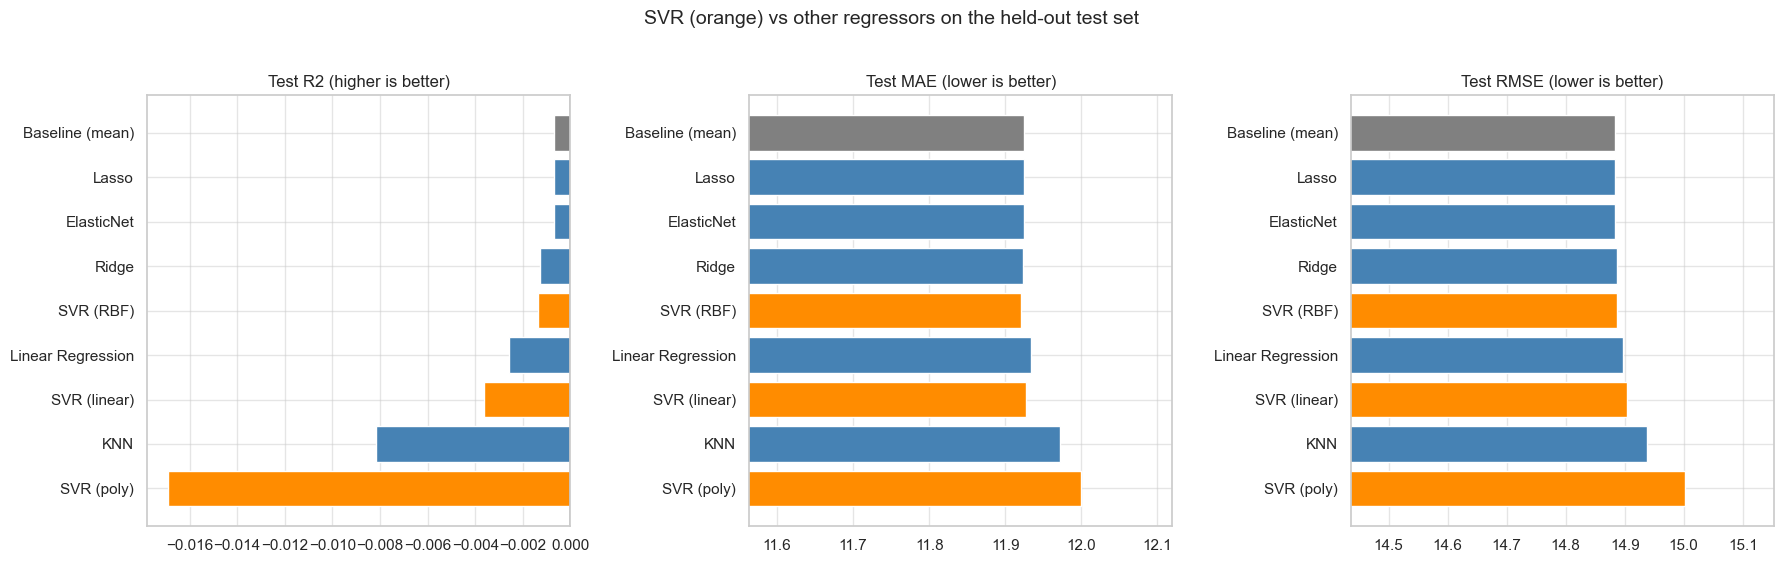

In [79]:
order = res.sort_values("Test_RMSE").index
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
colors = ["darkorange" if "SVR" in m else ("grey" if "Baseline" in m else "steelblue") for m in order]
for ax, metric, title in zip(axes, ["Test_R2", "Test_MAE", "Test_RMSE"], ["R2 (higher is better)", "MAE (lower is better)", "RMSE (lower is better)"]):
    vals = res.loc[order, metric]
    ax.barh(order, vals, color=colors); ax.set_title(f"Test {title}"); ax.invert_yaxis()
    if metric == "Test_R2":
        ax.axvline(0, color="black", lw=1)
    else:
        ax.set_xlim(vals.min() * 0.97, vals.max() * 1.01)
plt.suptitle("SVR (orange) vs other regressors on the held-out test set", fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

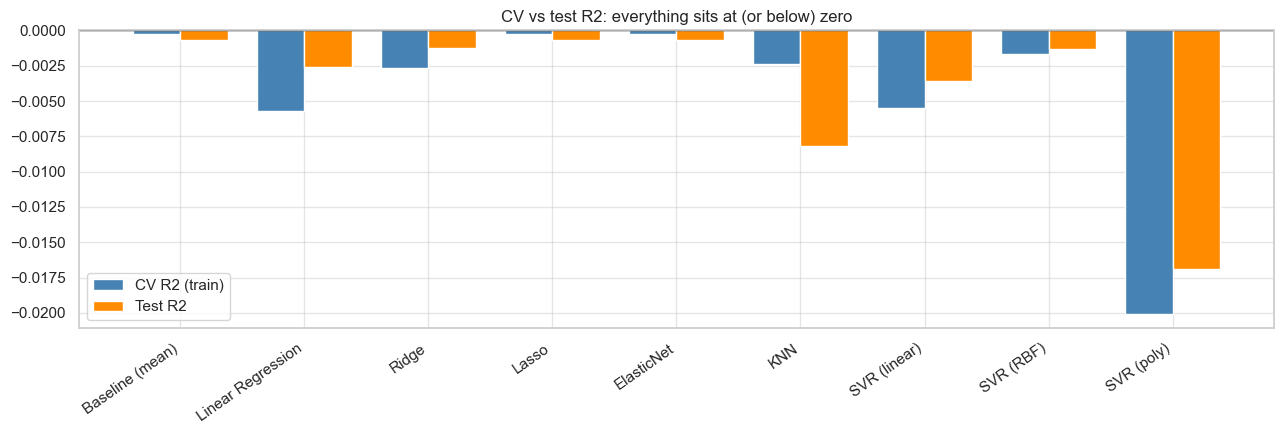

In [80]:
# Cross-validated R2 vs test R2 (tuning on CV can overfit; do the two agree?)
x = np.arange(len(res)); w = 0.38
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(x - w/2, res["CV_R2"], w, label="CV R2 (train)", color="steelblue")
ax.bar(x + w/2, res["Test_R2"], w, label="Test R2", color="darkorange")
ax.axhline(0, color="black", lw=1); ax.set_xticks(x); ax.set_xticklabels(res.index, rotation=35, ha="right")
ax.set_title("CV vs test R2: everything sits at (or below) zero"); ax.legend()
plt.tight_layout(); plt.show()

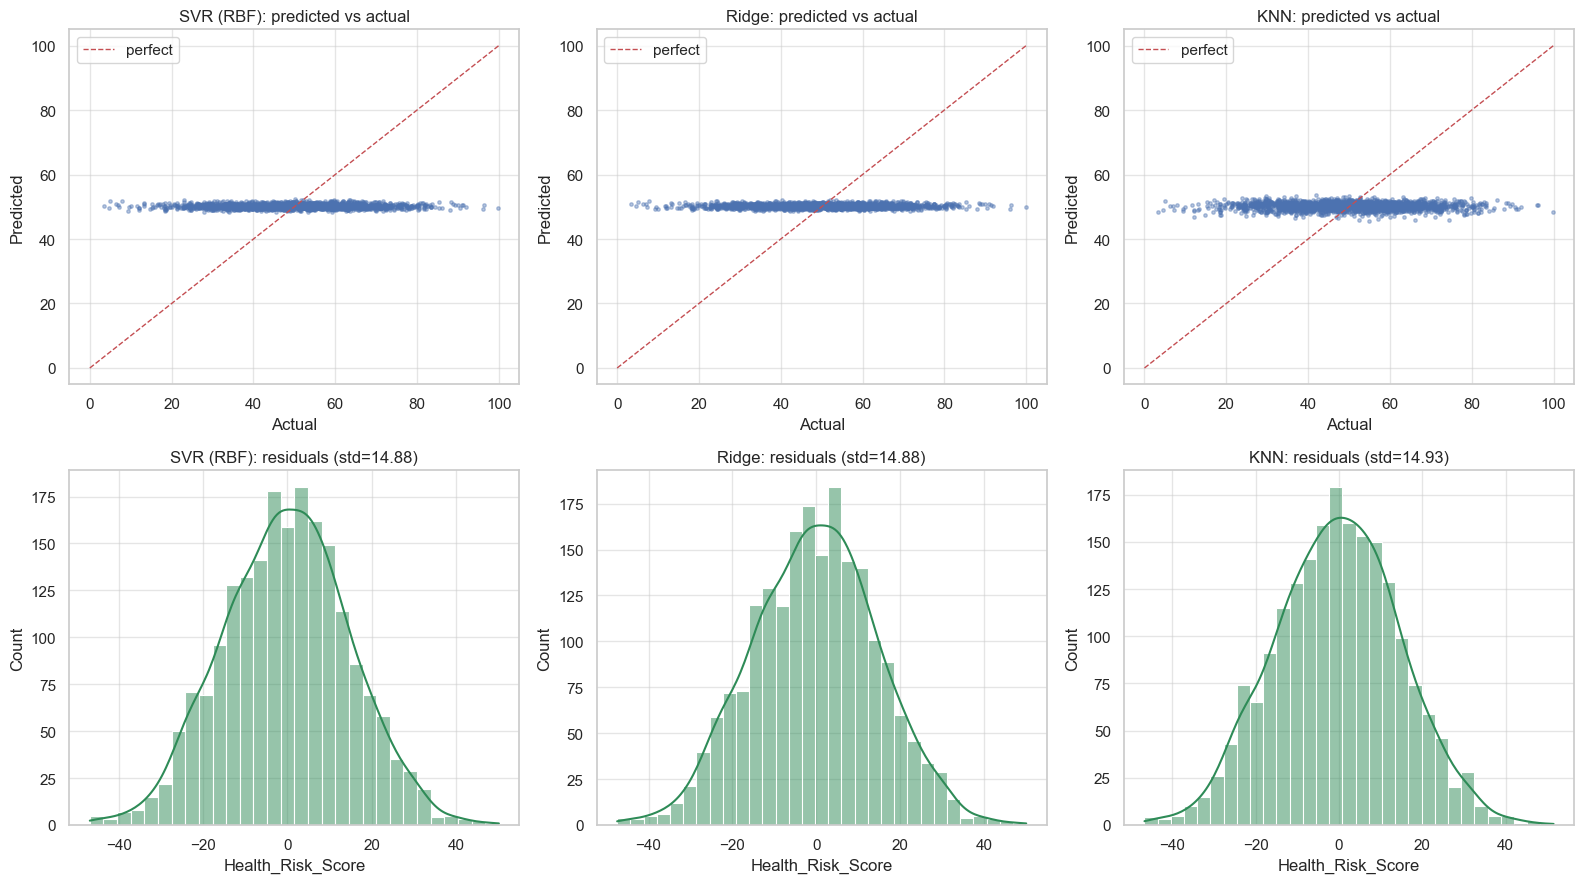

Best SVR kernel by CV R2: SVR (RBF)


In [81]:
# Predicted vs actual and residuals for the best SVR, the best linear model and KNN
svr_names = [m for m in res.index if "SVR" in m]
best_svr = res.loc[svr_names, "CV_R2"].idxmax()
show = [best_svr, "Ridge", "KNN"]
# Picks the best SVR kernel by CV R², then compares it with Ridge and KNN.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, name in enumerate(show):
    pred = fitted[name].predict(X_test)
    axes[0, j].scatter(y_test, pred, s=6, alpha=0.4)
    axes[0, j].plot([0, 100], [0, 100], "r--", lw=1, label="perfect")
    axes[0, j].set_title(f"{name}: predicted vs actual"); axes[0, j].set_xlabel("Actual"); axes[0, j].set_ylabel("Predicted"); axes[0, j].legend()
    sns.histplot(y_test - pred, kde=True, ax=axes[1, j], color="seagreen")
    axes[1, j].set_title(f"{name}: residuals (std={np.std(y_test - pred):.2f})")
plt.tight_layout(); plt.show()
print("Best SVR kernel by CV R2:", best_svr)

## 7. Why are the scores so low? Sanity checks

Every model lands near R2 = 0, i.e. no better than predicting the average score. Before blaming the models, we test whether the features contain any learnable signal at all.

In [82]:
# (a) Mutual information between each preprocessed feature and the target (captures non-linear dependence too)
Xt = preprocessor.fit_transform(X_train)
names = preprocessor.get_feature_names_out()
mi = pd.Series(mutual_info_regression(Xt, y_train, random_state=RANDOM_STATE), index=names).sort_values(ascending=False)
# Fits the preprocessor on the training data and measures mutual information between each transformed feature and the target.
# Unlike correlation, mutual information also catches non-linear dependence. All values were about 0.01, which is essentially nothing.
print("Highest mutual information (nats):")
print(mi.head(8).round(4).to_string())

# (b) Control experiment: same RBF-SVR trained on a SHUFFLED target (no signal by construction)
rbf_params = res.loc["SVR (RBF)", "Best_params"]
shuffled = y_train.sample(frac=1.0, random_state=RANDOM_STATE).values
ctrl = make(SVR(kernel="rbf", **rbf_params)).fit(X_train, shuffled)
# Takes the best RBF parameters and shuffles the training target, which destroys any real relationship with the features.
# Trains the same SVR on this fake target. If its test R² matches the real model’s, the real model has learned nothing real.
real = fitted["SVR (RBF)"]
print(f"\nRBF-SVR test R2 with the REAL target     : {r2_score(y_test, real.predict(X_test)):+.4f}")
print(f"RBF-SVR test R2 with a SHUFFLED target  : {r2_score(y_test, ctrl.predict(X_test)):+.4f}")

# (c) Noise ceiling: target std is how far off a constant guess is
print(f"\nTarget std = {y_test.std():.2f}  | baseline RMSE = {res.loc['Baseline (mean)', 'Test_RMSE']:.2f}  | best model RMSE = {res['Test_RMSE'].min():.2f}")

Highest mutual information (nats):
num__Glucose                        0.0122
cat__Age_Group_<30                  0.0114
cat__Age_Group_45-59                0.0108
cat__Family_History_No              0.0100
num__BMI                            0.0081
cat__BMI_Category_Overweight        0.0064
cat__Exercise_Frequency_Moderate    0.0063
cat__Family_History_Yes             0.0061

RBF-SVR test R2 with the REAL target     : -0.0013
RBF-SVR test R2 with a SHUFFLED target  : -0.0035

Target std = 14.88  | baseline RMSE = 14.88  | best model RMSE = 14.88


In [83]:
# (d) Does feature engineering help? 5-fold CV R2 with raw vs engineered features
def cv_r2(frame_train, model):
    pipe = TransformedTargetRegressor(
        regressor=Pipeline([("prep", build_preprocessor(frame_train)), ("model", model)]),
        transformer=StandardScaler())
    return cross_val_score(pipe, frame_train, y_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2").mean()
# Builds a fresh pipeline for whichever feature set you pass in, and returns its mean 5-fold CV R².

raw_cols = [c for c in clean_and_engineer(df, engineer=False).columns if c != TARGET] #The original columns only, without the engineered ones.
ablation = pd.DataFrame({
    "Raw features": [cv_r2(X_train[raw_cols], Ridge(alpha=100)), cv_r2(X_train[raw_cols], SVR(kernel="rbf", **rbf_params))],
    "+ Engineered": [cv_r2(X_train, Ridge(alpha=100)), cv_r2(X_train, SVR(kernel="rbf", **rbf_params))],
}, index=["Ridge(alpha=100)", "SVR (RBF)"]).round(4)
ablation

,Raw features,+ Engineered
Ridge(alpha=100),-0.0025,-0.0042
SVR (RBF),-0.0007,-0.0014


## 8. Save the final model

The final model is chosen **by cross-validated R2 on the training data** (never by test score). We save the best overall model and the best SVR; each file is a complete pipeline (imputation -> scaling -> encoding -> model -> inverse target scaling) that accepts a *cleaned/engineered* DataFrame, so we also keep the feature list.

In [84]:
candidates = res.drop(index="Baseline (mean)")
best_overall = candidates["CV_R2"].idxmax()
# Excludes the dummy baseline and picks the best model by CV R², which turned out to be Lasso.
print("Best overall (CV R2):", best_overall, "| Best SVR:", best_svr)

feature_cols = X_train.columns.tolist()
# Saves two bundles. 
# Each contains the whole fitted pipeline (imputer, scaler, encoder, model and target un-scaling), the expected column order, and the test metrics.
for tag, name in [("final_model", best_overall), ("best_svr_model", best_svr)]:
    joblib.dump({"pipeline": fitted[name], "model_name": name, "feature_columns": feature_cols,
                 "test_metrics": res.loc[name, ["Test_R2", "Test_MAE", "Test_RMSE"]].to_dict()},
                f"{tag}.joblib")
    print("saved", f"{tag}.joblib")

# --- reload and predict on new raw patients (cleaning function re-used) ---
bundle = joblib.load("final_model.joblib")
new_patients = pd.DataFrame([
    {"Patient_ID": 0, "Age": 45, "BMI": 28.1, "BloodPressure": 135, "Cholesterol": 230, "Glucose": 105,
     "Smoking_History": "Current", "Exercise_Frequency": "Rarely", "Alcohol_Consumption": np.nan, "Family_History": "Yes", TARGET: 0},
    {"Patient_ID": 1, "Age": 29, "BMI": 22.0, "BloodPressure": 112, "Cholesterol": 180, "Glucose": 88,
     "Smoking_History": "Never", "Exercise_Frequency": "Frequent", "Alcohol_Consumption": "Low", "Family_History": "No", TARGET: 0},
])
new_X = clean_and_engineer(new_patients).drop(columns=[TARGET])[bundle["feature_columns"]]
print("Model:", bundle["model_name"])
print("Predicted Health_Risk_Score:", bundle["pipeline"].predict(new_X).round(1))

Best overall (CV R2): Lasso | Best SVR: SVR (RBF)
saved final_model.joblib
saved best_svr_model.joblib
Model: Lasso
Predicted Health_Risk_Score: [50.2 50.2]


## 9. Conclusions

**Which model performed best?** No model beat the "always predict the mean" baseline. On the held-out test set every model has R2 between about -0.017 and 0.000, MAE ~ 11.9-12.0 and RMSE ~ 14.88-15.00 (target std = 14.88).

| Rank (CV R2) | Model | Test R2 | Test MAE | Test RMSE |
|---|---|---|---|---|
| 1 | Lasso / ElasticNet (shrink to the mean) | -0.0007 | 11.924 | 14.883 |
| 4 | **SVR (RBF)**, C=0.1, gamma=0.005 | -0.0013 | 11.921 | 14.888 |
| 8 | SVR (linear), C=0.01 | -0.0036 | 11.928 | 14.905 |
| 11 | SVR (polynomial, degree 2) | -0.0169 | 12.000 | 15.003 |

**Among the SVR kernels:** RBF > linear > polynomial. RBF and linear are equivalent to the baseline within noise; the polynomial kernel is the only one clearly *worse*, because its extra flexibility just fits noise.

**Why?**
1. *The features carry essentially no information about the target.* All correlations are ~0.00-0.01, mutual information is ~0.01 nats, and the target mean is the same in every category.
2. *The shuffled-target control* gives the same R2 (-0.0035 vs -0.0013), so the models are performing exactly as they would on pure noise.
3. *Model family doesn't matter:* linear, penalised, KNN, kernel and tree-based models all fail the same way. Lasso/ElasticNet succeed only by zeroing every coefficient, i.e. by becoming the mean predictor. More flexible models (poly SVR, KNN with few neighbours) do slightly worse because they overfit noise.
4. *Feature engineering did not help* (CV R2 raw vs engineered: Ridge -0.0025 vs -0.0042, SVR-RBF -0.0007 vs -0.0014).

**Caveats & next steps:** the saved `final_model.joblib` (Lasso) is effectively a constant ~50.2 predictor and should not be used for real risk decisions; `best_svr_model.joblib` is the best SVR. If this dataset is meant to have signal, check whether the target was generated from other variables that are missing from this file, or whether the labels were shuffled/misaligned. With a real signal, SVR-RBF would be expected to shine on smooth non-linear relationships with 10k rows, and the pipeline here (scaled target, tuned `C`/`gamma`/`epsilon`) can be reused unchanged.